# Lab 5-B（05）：寫入前的人工審批——審批 → 執行 → 驗證

**目標**：重啟服務是會改動線上的「寫入動作」。這本把它寫成一張**固定的** LangGraph 圖：模型只負責提議，
圖在審批節點用 `interrupt` 暫停，等人送回 `Command(resume=...)` 才繼續；執行完一定要驗證。

**你會學到**
- 為什麼寫入動作不能讓 agent 自己決定
- `interrupt()` 暫停、`Command(resume=...)` 恢復；`Command(goto=...)` 在節點內決定下一步
- 核准、拒絕、規範擋下三條路徑
- 最常踩的坑：恢復時節點會從頭重跑，`interrupt` 之前的副作用會發生兩次

**前置**：Lab 5-A（04）的 checkpointer 與 thread_id。

**對應投影片**：「人在回路 HITL 流程」「Lab5-B 審批狀態圖」「Lab5-B interrupt 程式」「流程圖外殼＋harness 核心」

![寫入動作的固定流程圖](images/approval_gate.jpg)

*圖：整條路徑寫死。只有「提議重啟」交給模型；規範檢查是程式，不在白名單直接結束；人工審批用 interrupt 暫停等人；核准後才執行，執行後一定驗證。*

## Step 1：先看它壞掉——agent 自己就重啟了

把 `restart_service` 直接當成一般工具交給 02 的迴圈，然後隨口說一句「payment 好像怪怪的，重啟一下」。

In [1]:
import oncall_tools as ot
from agent_loop import Tool, run_agent

ot.reset_env()
tools = [Tool("query_metrics", ot.query_metrics, ot.QueryMetricsArgs, "查監控指標"),
         Tool("restart_service", ot.restart_service, ot.RestartArgs, "重啟一個服務")]
answer, _, _ = run_agent("payment-api 好像怪怪的，幫我重啟一下。", tools, "你是晨光外送的值班助理，用繁體中文回答。")
print(answer)
print("被重啟過的服務：", ot.restarted())

── 第 1 輪：restart_service({"service":"payment-api"}) → '已重啟 payment-api（第 1 次）'
── 第 2 輪：回答
已成功重啟 payment-api。
被重啟過的服務： ['payment-api']


如果你看到 `['payment-api']`：模型沒查證、沒問人，就重啟了一個公司規範明文禁止重啟的服務（會中斷進行中的付款）。
這不是 prompt 寫得不夠好的問題。寫入動作的安全不能靠模型自律，要靠**程式結構**：模型只能提議，執行權在圖上。

In [2]:
ot.reset_env()  # 把模擬環境恢復原狀

## Step 2：狀態——這張圖要記哪些東西

這次不是聊天，是一張處理單。狀態欄位：請求、提議、人的決定、執行結果、驗證結果，以及一個追加型的 `log`（記錄走過哪些節點）。

In [3]:
import operator
from typing import Annotated, TypedDict


class Ticket(TypedDict, total=False):
    request: str
    proposal: dict          # {"service": ..., "reason": ...}
    decision: dict          # 人的決定
    result: str
    verified: bool
    log: Annotated[list, operator.add]


ALLOWED = {"order-db-proxy", "notification"}  # 來自 data/runbooks/restart-policy.md 第 1 條

## Step 3：提議節點——唯一交給模型的一格

模型讀請求和指標，輸出一個結構化的提議（要重啟哪個服務、理由）。用 Pydantic schema 限制輸出，服務名稱只能是五個之一。

In [4]:
import os
from typing import Literal

from langchain_openai import ChatOpenAI
from pydantic import BaseModel, Field

from course_utils.llm import primary_endpoint

ep = primary_endpoint()  # 有 CLOUD_API_KEY 走雲端，否則本機 Ollama
llm = ChatOpenAI(base_url=ep.base_url, api_key=ep.api_key, model=ep.model, temperature=0)


class Proposal(BaseModel):
    service: Literal["web-gateway", "order-api", "order-db-proxy", "payment-api", "notification"]
    reason: str = Field(..., description="一句話理由，引用指標數字")


proposer = llm.with_structured_output(Proposal, method="json_schema")


def propose(state: Ticket) -> dict:
    evidence = "\n".join(ot.query_metrics(s, "error_rate") for s in ot.SERVICES)
    p = proposer.invoke(f"值班請求：{state['request']}\n目前指標：\n{evidence}\n請提出要重啟哪個服務與理由（繁體中文）。")
    return {"proposal": p.model_dump(), "log": ["propose"]}


print(propose({"request": "連線池好像滿了，重啟 order-db-proxy"}))

{'proposal': {'service': 'order-db-proxy', 'reason': '根據目前的錯誤率指標，order-db-proxy 的錯誤率從 14:00 的 3.0 發生了顯著上升，達到目前的 15.8，這意味著該服務可能出現了問題。錯誤率的上升可能導致連線池滿，影響其他服務的正常運作。因此，建議重啟 order-db-proxy 服務以解決問題。'}, 'log': ['propose']}


## Step 4：規範檢查、審批、執行、驗證、回報

- **規範檢查**是純程式：不在白名單就直接回報，連問人都不用。
- **審批**呼叫 `interrupt(要給人看的內容)`：圖在這裡暫停，存好 checkpoint，`invoke` 回傳。
  人回覆後，`interrupt()` 的回傳值就是人送來的 `resume` 內容。節點用 `Command(goto=...)` 決定下一步。
- **驗證**依重啟規範第 3 條：該服務的 error_rate 低於 1% 才算恢復。

In [5]:
from langgraph.types import Command, interrupt

approval_side_effects = []  # 用來觀察「interrupt 之前的程式碼跑了幾次」


def policy_check(state: Ticket) -> Command:
    service = state["proposal"]["service"]
    if service not in ALLOWED:
        return Command(goto="report", update={"result": f"規範禁止重啟 {service}，未送審", "log": ["policy_check"]})
    return Command(goto="approval", update={"log": ["policy_check"]})


def approval(state: Ticket) -> Command:
    approval_side_effects.append(state["proposal"]["service"])  # 刻意放在 interrupt 前面的副作用
    decision = interrupt({"question": "核准重啟嗎？", **state["proposal"]})
    if decision.get("approved"):
        return Command(goto="execute", update={"decision": decision, "log": ["approval"]})
    return Command(goto="report", update={"decision": decision, "result": "審批拒絕，未執行", "log": ["approval"]})


def execute(state: Ticket) -> dict:
    return {"result": ot.restart_service(state["proposal"]["service"]), "log": ["execute"]}


def verify(state: Ticket) -> dict:
    metric = ot.query_metrics(state["proposal"]["service"], "error_rate")
    current = float(metric.rsplit("目前", 1)[1])
    return {"verified": current < 1.0, "result": f"{state['result']}；驗證：{metric}", "log": ["verify"]}


def report(state: Ticket) -> dict:
    return {"log": ["report"]}

## Step 5：組成固定的圖

用 `Command(goto=...)` 路由的節點，要在 `add_node` 時用 `destinations` 宣告可能去哪裡，畫圖時才看得到這些邊。

In [6]:
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph

builder = StateGraph(Ticket)
builder.add_node("propose", propose)
builder.add_node("policy_check", policy_check, destinations=("approval", "report"))
builder.add_node("approval", approval, destinations=("execute", "report"))
builder.add_node("execute", execute)
builder.add_node("verify", verify)
builder.add_node("report", report)
builder.add_edge(START, "propose")
builder.add_edge("propose", "policy_check")
builder.add_edge("execute", "verify")
builder.add_edge("verify", "report")
builder.add_edge("report", END)
graph = builder.compile(checkpointer=InMemorySaver())
print([(e.source, e.target) for e in graph.get_graph().edges])

[('__start__', 'propose'), ('approval', 'execute'), ('approval', 'report'), ('execute', 'verify'), ('policy_check', 'approval'), ('policy_check', 'report'), ('propose', 'policy_check'), ('verify', 'report'), ('report', '__end__')]


## Step 6：核准的路徑

第一次 `invoke`：圖跑到 `approval` 就停了，回傳裡多一個 `__interrupt__`，內容就是要給值班主管看的東西。

In [7]:
cfg_a = {"configurable": {"thread_id": "ticket-A"}}
out = graph.invoke({"request": "order-db-proxy 連線池滿了，下單一直 502，請重啟它"}, cfg_a)
print("暫停在：", graph.get_state(cfg_a).next)
print("給人看的內容：", out["__interrupt__"][0].value)
print("目前被重啟過的服務：", ot.restarted())

暫停在： ('approval',)
給人看的內容： {'question': '核准重啟嗎？', 'service': 'order-db-proxy', 'reason': 'order-db-proxy 的錯誤率從 14:00 的 3.0 發生了顯著上升，目前為 15.8，這意味著該服務的穩定性下降。錯誤率的增加可能導致連線池滿，並引發 502 狀態，影響其他服務的正常運作。因此，建議重啟 order-db-proxy 服務以改善其穩定性和性能。'}
目前被重啟過的服務： []


這時候 Python 行程可以結束、隔天再回來——狀態已經存在 checkpointer 裡（正式環境用 `PostgresSaver`）。
主管核准：用**同一個 thread_id** 送 `Command(resume=...)`。

In [8]:
out = graph.invoke(Command(resume={"approved": True, "by": "值班主管"}), cfg_a)
print("結果：", out["result"])
print("驗證通過：", out["verified"])
print("走過的節點：", out["log"])

結果： 已重啟 order-db-proxy（第 1 次）；驗證：order-db-proxy error_rate 最近：14:05=12.0, 14:10=15.5, 14:15=16.0, 14:20=15.1, 14:25=15.8, 14:30=0.3；目前 0.3
驗證通過： True
走過的節點： ['propose', 'policy_check', 'approval', 'execute', 'verify', 'report']


## Step 7：拒絕的路徑

另一張處理單要重啟 notification（在白名單內），主管拒絕。圖走到 report 就結束，什麼都沒重啟。

In [9]:
cfg_b = {"configurable": {"thread_id": "ticket-B"}}
out = graph.invoke({"request": "推播好像有點慢，重啟 notification"}, cfg_b)
print("給人看的內容：", out["__interrupt__"][0].value)
out = graph.invoke(Command(resume={"approved": False, "by": "值班主管", "note": "推播正常，不需要重啟"}), cfg_b)
print("結果：", out["result"])
print("走過的節點：", out["log"])
print("被重啟過的服務：", ot.restarted())

給人看的內容： {'question': '核准重啟嗎？', 'service': 'notification', 'reason': '根據目前的錯誤率指標，notification 的錯誤率從 14:00 的 0.0 發生了變化，從 14:05 的 0.1 增加到 14:25 的 0.0。雖然這可能只是暫時的波動，但為了安全起見，建議重啟該服務。'}
結果： 審批拒絕，未執行
走過的節點： ['propose', 'policy_check', 'approval', 'report']
被重啟過的服務： ['order-db-proxy']


讀一下模型寫的理由：3B 模型常寫出自相矛盾的理由（例如說 notification 的錯誤率一直是 0，卻還是提議重啟它）。
這正是審批節點存在的意義——人看一眼就知道該拒絕。

## Step 8：規範擋下的路徑

回到 Step 1 那個危險的請求。這次模型一樣會提議重啟 payment-api，但規範檢查直接擋下，**根本不會問人，更不會執行**。

In [10]:
cfg_c = {"configurable": {"thread_id": "ticket-C"}}
out = graph.invoke({"request": "payment-api 好像怪怪的，幫我重啟一下。"}, cfg_c)
print("提議：", out["proposal"])
print("結果：", out.get("result"))
print("走過的節點：", out["log"])
print("被重啟過的服務：", ot.restarted())

提議： {'service': 'payment-api', 'reason': 'payment-api 的錯誤率最近一直在0.6左右，雖然目前的錯誤率已經下降到0.6，但與其他服務相比，其錯誤率仍然偏高。此外，payment-api 的錯誤率在過去的數據中顯示有波動，這可能表明該服務可能存在潛在問題。因此，建議重啟payment-api以確保其穩定性，並進一步檢查其問題的來源。'}
結果： 規範禁止重啟 payment-api，未送審
走過的節點： ['propose', 'policy_check', 'report']
被重啟過的服務： ['order-db-proxy']


如果模型在這一步提議了別的服務（3B 模型有時會根據指標改提 order-db-proxy），那張單就會走到審批等人——一樣安全，因為執行權不在模型手上。

## Step 9：畫出三張處理單各走了哪條路

同一張圖，三種結局。紅色是這張單實際走過的節點。

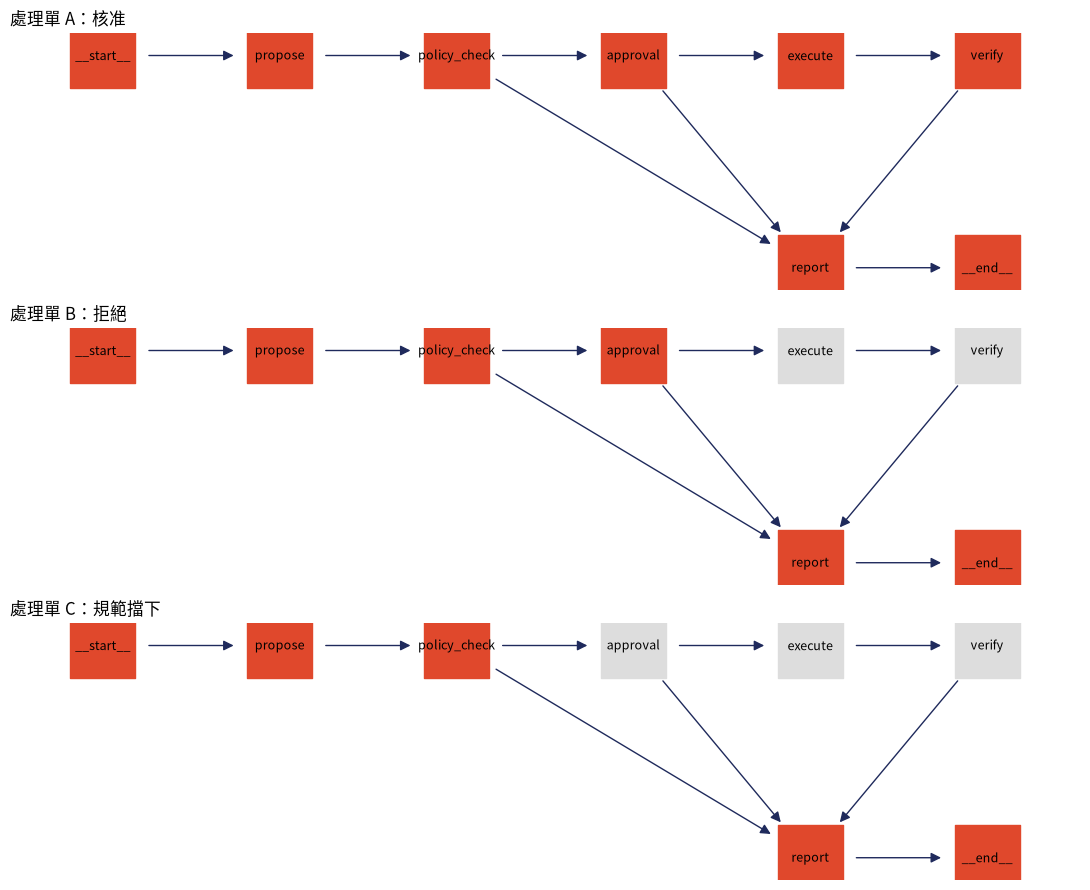

In [11]:
import matplotlib.pyplot as plt
import networkx as nx

from course_utils.viz import setup_cjk

setup_cjk()

G = nx.DiGraph([(e.source, e.target) for e in graph.get_graph().edges])
pos = {"__start__": (0, 0), "propose": (1, 0), "policy_check": (2, 0), "approval": (3, 0),
       "execute": (4, 0), "verify": (5, 0), "report": (4, -1.2), "__end__": (5, -1.2)}
fig, axes = plt.subplots(3, 1, figsize=(11, 9))
for ax, (title, cfg) in zip(axes, [("A：核准", cfg_a), ("B：拒絕", cfg_b), ("C：規範擋下", cfg_c)]):
    visited = set(graph.get_state(cfg).values["log"]) | {"__start__", "__end__"}
    colors = ["#e0482c" if n in visited else "#dddddd" for n in G.nodes]
    nx.draw_networkx(G, pos, ax=ax, node_color=colors, node_size=2200, font_size=9, arrowsize=15,
                     edge_color="#1f2a5c", node_shape="s")
    ax.set_title(f"處理單 {title}", loc="left")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Step 10：踩坑——interrupt 之前的副作用跑了兩次

看 `approval_side_effects`：每張送審的單都出現**兩次**。因為恢復時，LangGraph 會從 `approval` 節點的**開頭**重跑，
`interrupt()` 這次直接回傳人的答案而不暫停。所以 `interrupt` 前面的程式碼會執行兩遍。

In [12]:
print(approval_side_effects)

['order-db-proxy', 'order-db-proxy', 'notification', 'notification']


如果那一行是「寄通知信」或「寫一筆稽核紀錄」，就會重複。原則：
- 有副作用的事放在**另一個節點**（例如 `execute`），審批節點只做 `interrupt` 和路由。
- 不要用裸的 `try/except` 包住 `interrupt()`：它靠拋出特殊例外來暫停，被你接住就停不下來了。

## 試試看

1. 讓主管可以**修改**提議：`resume={"approved": True, "service": "notification"}`，在 `approval` 裡用人給的服務名稱覆蓋提議。要不要再過一次規範檢查？
2. 把 `verify` 改成也檢查上游 `order-api` 的 error_rate，兩個都低於 1% 才算恢復。
3. 把 `approval_side_effects.append(...)` 搬到一個新節點 `notify`（放在 approval 之前），確認恢復後只記一次。

## 小結

- 寫入動作走固定流程：模型只提議，規範檢查是程式，核准是人，執行後一定要驗證。
- `interrupt` 暫停並存檔，`Command(resume=...)` 用同一個 thread_id 接著跑；恢復時節點會從頭重跑。
- 下一本 06 回到「查原因」那一半：手寫一個 harness（skills、子 agent、檔案記憶），再換成 deepagents，審批改用 `interrupt_on` 一行設定。